# Project: Model Analysis and Pipeline Implementation
**Goal:** Compare a fine-tuned large model (Mixtral) with a smaller classifier (BERT), then build a reusable Scikit-learn pipeline driven by a YAML file.

## Step 1: 
Setup - load the model performance metrics

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("C:/Users/user/Desktop/Agentic AI Coursera/synthetic_ticket_data.csv")
df

,Model,Accuracy,Precision,Recall,F1,Train_Time_s,Latency_ms_per_prediction,Model_Size_KB
0,Small model (LogisticRegression),0.55,0.500,0.222,0.308,0.033,1.323,1.9
1,"Larger model (RandomForest, 300 trees)",0.45,0.375,0.333,0.353,0.349,9.749,1232.7
2,Mixtral (fine-tuned large model),0.65,0.565,0.444,0.379,0.577,11.119,1448.6
3,BERT (small classifier),0.75,0.775,0.555,0.399,0.742,13.789,1668.9


## Step 2: Written analysis
.

In [3]:
compare = df[df["Model"].str.contains("Mixtral|BERT")].set_index("Model")
compare = compare[["Accuracy", "Precision", "Recall", "F1",
                   "Latency_ms_per_prediction", "Train_Time_s", "Model_Size_KB"]]
display(compare)

# BERT minus Mixtral for each metric
diff = (compare.loc["BERT (small classifier)"] - compare.loc["Mixtral (fine-tuned large model)"]).round(3)
print("BERT minus Mixtral:")
print(diff)

,Accuracy,Precision,Recall,F1,Latency_ms_per_prediction,Train_Time_s,Model_Size_KB
Model,,,,,,,
Mixtral (fine-tuned large model),0.65,0.565,0.444,0.379,11.119,0.577,1448.6
BERT (small classifier),0.75,0.775,0.555,0.399,13.789,0.742,1668.9


BERT minus Mixtral:
Accuracy                       0.100
Precision                      0.210
Recall                         0.111
F1                             0.020
Latency_ms_per_prediction      2.670
Train_Time_s                   0.165
Model_Size_KB                220.300
dtype: float64


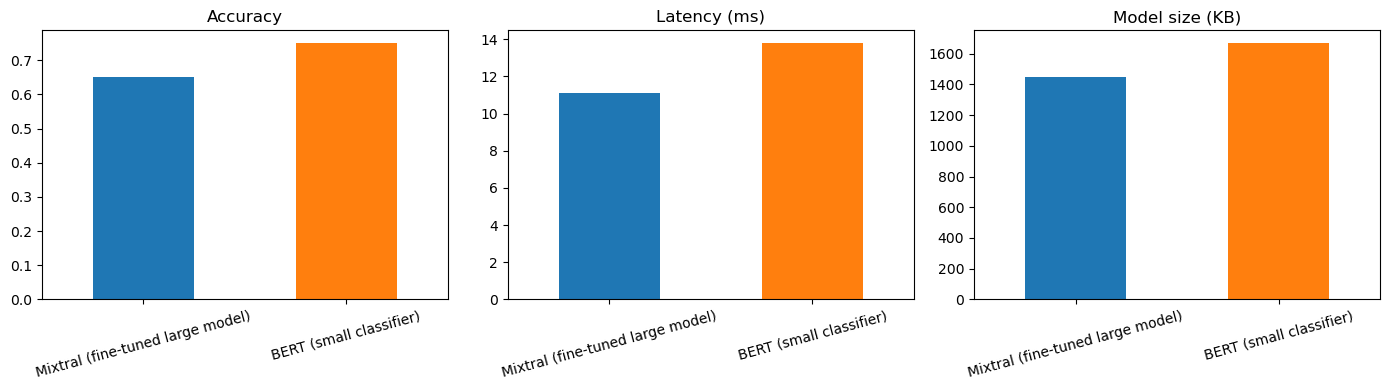

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

compare["Accuracy"].plot(kind="bar", ax=axes[0], title="Accuracy", color=["#1f77b4", "#ff7f0e"])
compare["Latency_ms_per_prediction"].plot(kind="bar", ax=axes[1], title="Latency (ms)", color=["#1f77b4", "#ff7f0e"])
compare["Model_Size_KB"].plot(kind="bar", ax=axes[2], title="Model size (KB)", color=["#1f77b4", "#ff7f0e"])

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()


- **Accuracy:** BERT is better, with 0.75 against 0.65 for Mixtral, a gain of 0.10. BERT also leads in precision (0.775 vs 0.565), recall (0.555 vs 0.444) and F1 (0.399 vs 0.379).
- **Latency:** Mixtral is faster at 11.12 ms per prediction against 13.79 ms for BERT. Lower latency matters for real-time use such as live ticket routing.
- **Cost:** Mixtral is cheaper. It trains in 0.577 s against 0.742 s and is smaller at 1448.6 KB against 1668.9 KB.
- **Verdict:** I choose BERT. It is clearly more accurate, and the extra latency (2.67 ms) and cost are small. Mixtral is only better if speed is the top priority.
- **Note:** These metrics are synthetic/simulated, so the conclusion should be confirmed on real data

## Step 3: Pipeline configuration (YAML)
The pipeline is described in a YAML file, so changing settings never requires changing code.

In [6]:
config_text = """\
pipeline:
  name: ticket_text_classifier
  version: "1.0.0"

data:
  source: sklearn_20newsgroups
  categories: [sci.space, rec.sport.baseball]
  test_size: 0.2
  random_state: 42

preprocessing:
  tfidf:
    max_features: 5000
    ngram_range: [1, 2]
    stop_words: english

model:
  type: logistic_regression
  params:
    C: 1.0
    max_iter: 1000
    random_state: 42

output:
  model_dir: models
"""

with open("pipeline_config.yaml", "w") as f:
    f.write(config_text)

print(open("pipeline_config.yaml").read())  

pipeline:
  name: ticket_text_classifier
  version: "1.0.0"

data:
  source: sklearn_20newsgroups
  categories: [sci.space, rec.sport.baseball]
  test_size: 0.2
  random_state: 42

preprocessing:
  tfidf:
    max_features: 5000
    ngram_range: [1, 2]
    stop_words: english

model:
  type: logistic_regression
  params:
    C: 1.0
    max_iter: 1000
    random_state: 42

output:
  model_dir: models



## Step 4: Reusable Scikit-learn pipeline (Python script)
Modular functions: load config, load data, build pipeline, train and evaluate, save.

In [7]:
%%writefile pipeline.py
"""Reusable text-classification pipeline driven by a YAML config."""
import os
import yaml
import joblib
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report


def load_config(path="pipeline_config.yaml"):
    with open(path) as f:
        return yaml.safe_load(f)


def load_data(cfg):
    d = cfg["data"]
    data = fetch_20newsgroups(
        subset="all",
        categories=d["categories"],
        remove=("headers", "footers", "quotes"),
    )
    return train_test_split(
        data.data, data.target,
        test_size=d["test_size"],
        random_state=d["random_state"],
        stratify=data.target,
    )


def build_pipeline(cfg):
    t = cfg["preprocessing"]["tfidf"]
    tfidf = TfidfVectorizer(
        max_features=t["max_features"],
        ngram_range=tuple(t["ngram_range"]),
        stop_words=t["stop_words"],
    )
    model = LogisticRegression(**cfg["model"]["params"])
    return Pipeline([("tfidf", tfidf), ("clf", model)])


def train_and_evaluate(pipe, X_train, X_test, y_train, y_test):
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print(classification_report(y_test, preds))
    return pipe


def save_pipeline(pipe, cfg):
    out_dir = cfg["output"]["model_dir"]
    os.makedirs(out_dir, exist_ok=True)
    name, version = cfg["pipeline"]["name"], cfg["pipeline"]["version"]
    path = os.path.join(out_dir, f"{name}_v{version}.joblib")
    joblib.dump(pipe, path)
    print("Saved:", path)
    return path


def main(config_path="pipeline_config.yaml"):
    cfg = load_config(config_path)
    X_train, X_test, y_train, y_test = load_data(cfg)
    pipe = build_pipeline(cfg)
    pipe = train_and_evaluate(pipe, X_train, X_test, y_train, y_test)
    save_pipeline(pipe, cfg)
    return pipe


if __name__ == "__main__":
    main()

Overwriting pipeline.py


## Step 5: 
Run the pipeline

In [8]:
!pip install pyyaml joblib -q
from pipeline import main
pipe = main()

Accuracy: 0.9496
              precision    recall  f1-score   support

           0       0.95      0.95      0.95       199
           1       0.95      0.95      0.95       198

    accuracy                           0.95       397
   macro avg       0.95      0.95      0.95       397
weighted avg       0.95      0.95      0.95       397

Saved: models\ticket_text_classifier_v1.0.0.joblib


In [10]:
# Quick test of the saved pipeline
print(pipe.predict(["NASA launched a new rocket to the moon",
                    "The pitcher threw a no-hitter last night"]))
# 0 = rec.sport.baseball, 1 = sci.space

[1 0]


## Step 6: 
Accountability notes

In [19]:
compliance_check(min_accuracy=0.90, accuracy=0.9496, reviewer="ML Engineer")

,check,passed,checked_by,date
0,Version defined in YAML,True,ML Engineer,2026-11-16
1,Random seed set (reproducible),True,ML Engineer,2026-11-16
2,Model file saved with version,True,ML Engineer,2026-11-16
3,Accuracy >= 0.9,True,ML Engineer,2026-11-16


In [2]:
from IPython.display import Markdown
Markdown("### Accountability Notes\n" + "\n".join(f"- **{k}:** {v}" for k, v in accountability.items()))

### Accountability Notes
- **Responsible person/role:** ML Engineer
- **What they check:** config version, seed, metrics, model file
- **How (method/tool):** compliance_check(), Git review
- **How often:** every release, monthly
- **Where it is recorded:** compliance_log.csv, Git history

## SETP 7
Reflections

In [4]:
import re
from IPython.display import Markdown

sentences = [s.strip() for s in re.split(r"[.!?]+", reflection) if s.strip()]
print(f"Sentences: {len(sentences)} (target: 4-6)")
Markdown("### Reflection\n" + reflection.strip())

Sentences: 4 (target: 4-6)


### Reflection
The YAML config keeps every setting in one file, so anyone can rerun the same experiment without editing code. The fixed random_state makes the train/test split and the model training give the same results on every run. The modular script splits the work into small functions, so each part can be tested or changed without breaking the rest. The versioned model file name lets us tell releases apart and roll back to an earlier model if needed.